In [45]:
# Necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [34]:
def clean(filepath):
    data = pd.read_csv(filepath)

    # Rename first columns
    new_columns = {"Country Name": "country_name", "Series Name": "series_name"}
    data.rename(columns=new_columns, inplace=True)

    # Rename year columns
    data.rename(
        columns={f"{year} [YR{year}]": str(year) for year in range(2000, 2025)},
        inplace=True,
    )

    # Remove Country Code and Series Code columns
    data.drop(columns=["Country Code", "Series Code"], inplace=True)

    # Remove the bottom 5 rows
    data = data.iloc[:-5].copy()

    # Replace ".." with missing values
    year_columns = [str(year) for year in range(2000, 2025)]
    data[year_columns] = data[year_columns].replace("..", float("nan"))

    # Convert year columns to float
    data[year_columns] = data[year_columns].astype(float)

    return data

In [35]:
# Loading necessary datasets
df_combined = clean("data/combined_dataset.csv")
df_gdp_leb = clean("data/gdp_leb.csv")
df_gdp_uet = clean("data/gdp_uet.csv")

In [ ]:
# Descriptive Statistics
year_columns = [str(year) for year in range(2000, 2025)]
df_combined.groupby("series_name")[year_columns].describe()

2000               \
                                                    count         mean   
series_name                                                              
GDP per capita (current US$)                        252.0  7558.701094   
Life expectancy at birth, total (years)             265.0    67.152136   
Unemployment, total (% of total labor force) (n...  143.0     8.141275   

                                                                              \
                                                             std         min   
series_name                                                                    
GDP per capita (current US$)                        12221.780769  122.269203   
Life expectancy at birth, total (years)                 9.418098   44.834000   
Unemployment, total (% of total labor force) (n...      5.752231    0.400000   

                                                                             \
                                                           25%          50%   
series_name                                                                   
GDP per capita (current US$)                        632.446663  1781.863176   
Life expectancy at birth, total (years)              61.207000    70.026000   
Unemployment, total (% of total labor force) (n...    4.074958     6.488000   

                                                                               \
                                                            75%           max   
series_name                                                                     
GDP per capita (current US$)                        8377.655117  81789.014509   
Life expectancy at birth, total (years)               74.409000     82.121000   
Unemployment, total (% of total labor force) (n...    11.161500     32.200000   

                                                     2001               ...  \
                                                    count         mean  ...   
series_name                                                             ...   
GDP per capita (current US$)                        253.0  7566.190690  ...   
Life expectancy at birth, total (years)             265.0    67.493584  ...   
Unemployment, total (% of total labor force) (n...  150.0     8.949605  ...   

                                                            2023  \
                                                             75%   
series_name                                                        
GDP per capita (current US$)                        24857.123156   
Life expectancy at birth, total (years)                78.391234   
Unemployment, total (% of total labor force) (n...      6.995000   

                                                                    2024  \
                                                              max  count   
series_name                                                                
GDP per capita (current US$)                        256799.911212  248.0   
Life expectancy at birth, total (years)                 86.372000  265.0   
Unemployment, total (% of total labor force) (n...      35.190000  125.0   

                                                                  \
                                                            mean   
series_name                                                        
GDP per capita (current US$)                        20632.779344   
Life expectancy at birth, total (years)                73.674918   
Unemployment, total (% of total labor force) (n...      6.368466   

                                                                              \
                                                             std         min   
series_name                                                                    
GDP per capita (current US$)                        32816.899317  216.231929   
Life expectancy at birth, total (years)                 6.928571   54.635000   
Unemployment, t

In [93]:
mean_data = df_combined.groupby("series_name")[year_columns].mean()
mean_data_transposed = mean_data.T
mean_data_transposed.describe()

series_name,GDP per capita (current US$),"Life expectancy at birth, total (years)","Unemployment, total (% of total labor force) (national estimate)"
count,25.000000,25.000000,25.000000
mean,14969.874393,70.634646,7.781453
std,3845.095869,1.928346,0.761422
min,7558.701094,67.152136,6.214356
25%,12935.599723,69.128489,7.531677
50%,15805.905708,71.081450,7.850532
75%,17336.772641,72.146735,8.277342
max,20632.779344,73.674918,9.149862


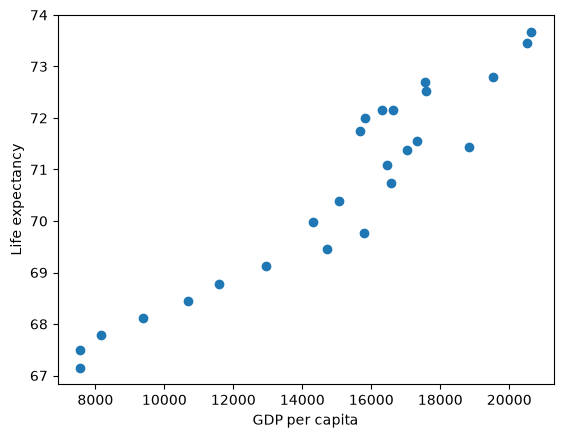

In [100]:
# Question 5: Within each country, how do changes in GDP per capita relate to changes in life expectancy?
gdp = mean_data_transposed["GDP per capita (current US$)"]
leb = mean_data_transposed["Life expectancy at birth, total (years)"]

plt.scatter(gdp, leb)

plt.xlabel("GDP per capita")
plt.ylabel("Life expectancy")
plt.show()

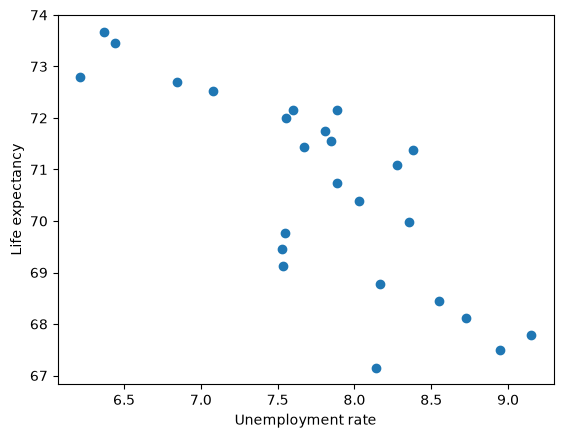

In [95]:
# Question 6: How is unemployment related to life expectancy?
uet = mean_data_transposed[
    "Unemployment, total (% of total labor force) (national estimate)"
]
plt.scatter(uet, leb)

plt.xlabel("Unemployment rate")
plt.ylabel("Life expectancy")
plt.show()

In [97]:
# Question 7: Which countries have high GDP per capita but also high unemployment?
country_data = (
    df_combined.groupby(["country_name", "series_name"])[year_columns]
    .mean()
    .mean(axis=1)
    .unstack("series_name")
)

gdp_column = "GDP per capita (current US$)"
uet_column = "Unemployment, total (% of total labor force) (national estimate)"
leb_column = "Life expectancy at birth, total (years)"

high_gdp = country_data[gdp_column] > country_data[gdp_column].median()

high_uet = country_data[uet_column] > country_data[uet_column].median()

countries_gdp_uet = country_data[high_gdp & high_uet].drop(
    columns="Life expectancy at birth, total (years)"
)

print(countries_gdp_uet.count())

series_name
GDP per capita (current US$)                                        72
Unemployment, total (% of total labor force) (national estimate)    72
dtype: int64


In [102]:
# Question 8: Which countries have low GDP per capita but relatively high life expectancy?
low_gdp = ~high_gdp

high_leb = country_data[leb_column] > country_data[leb_column].median()

countries_gdp_leb = country_data[low_gdp & high_leb].drop(
    columns="Unemployment, total (% of total labor force) (national estimate)"
)

print(countries_gdp_uet.count())

series_name
GDP per capita (current US$)                                        72
Unemployment, total (% of total labor force) (national estimate)    72
dtype: int64
